### 1. Kütüphanelerin Yüklenmesi ve Ham Verilerin Okunması
Bu hücrede analiz sürecinde ihtiyaç duyulan temel veri işleme kütüphaneleri (`pandas`, `numpy`) ile görselleştirme araçları (`matplotlib`, `seaborn`) çalışma alanına dahil edilmektedir.

Excel dosyasında (`degerlendirme_veri.xlsx`) yer alan 3 bağımsız çalışma sayfası okunarak ayrı DataFrame yapılarına aktarılmıştır:
* **`df_ogrenciler`:** Öğrenci numarası, adı-soyadı ve şube/grup bilgilerini içerir.
* **`df_sinav`:** Günlük uygulanan 0–100 ölçeğindeki tek sınav notlarını tutar.
* **`df_degerlendirme`:** Günlük sınıf içi performansa göre verilen 0–10 ölçeğindeki puanları tutar.

İlk olarak `df_ogrenciler` tablosunun ilk 5 satırı ekrana basılarak veri yapısı doğrulanmıştır.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dosya_yolu = "degerlendirme_veri.xlsx"

df_ogrenciler = pd.read_excel(dosya_yolu, sheet_name="Ogrenciler")
df_sinav = pd.read_excel(dosya_yolu, sheet_name="Gunluk_Sinav")
df_degerlendirme = pd.read_excel(dosya_yolu, sheet_name="Gunluk_Degerlendirme")

print("Öğrenciler Tablosu:")
display(df_ogrenciler.head())

Öğrenciler Tablosu:


,No,Ad Soyad,Grup
0,1,Ahmet Yıldırım,A
1,2,Mehmet Demir,B
2,3,Ayşe Kaya,C
3,4,Fatma Şahin,A
4,5,Hasan Arslan,B


### 2. Tablo Doğrulamaları ve Gruplara Göre Öğrenci Dağılımı (Madde 1)
Bu hücrede ilk olarak `df_sinav` ve `df_degerlendirme` tablolarının sütun başlıkları ve ilk kayıtları listelenerek veri kalitesi teyit edilmektedir.

Ardından 1. madde kapsamında `df_ogrenciler` tablosundaki `Grup` sütunu taranmış; `value_counts()` fonksiyonu ile A, B ve C gruplarında kayıtlı toplam öğrenci sayıları hesaplanmıştır. Elde edilen frekans dağılımı `seaborn.barplot` ile sütun grafiğine aktarılmıştır.

Günlük Sınav Tablosu:


,Tarih,No,Not,Sinav_Norm
0,2022-10-10,1,50.0,0.5
1,2022-10-10,2,100.0,1.0
2,2022-10-10,3,100.0,1.0
3,2022-10-10,4,100.0,1.0
4,2022-10-10,5,100.0,1.0



Günlük Değerlendirme Tablosu:


,Tarih,No,Puan,Degerlendirme_Norm
0,2022-10-10,1,3,0.333333
1,2022-10-10,2,6,0.666667
2,2022-10-10,3,6,0.666667
3,2022-10-10,4,6,0.666667
4,2022-10-10,5,6,0.666667



--- Gruplara Göre Öğrenci Dağılımı ---
Grup
A    17
B    17
C    16
Name: count, dtype: int64


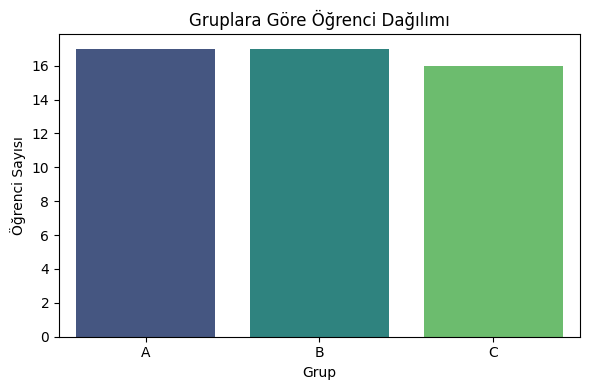

In [ ]:
# Sınav ve değerlendirme tablolarının ilk 5 satırını ekrana basarak sütun yapılarını doğrular
print("Günlük Sınav Tablosu:")
display(df_sinav.head())

print("\nGünlük Değerlendirme Tablosu:")
display(df_degerlendirme.head())

# 1. Madde: Öğrencilerin gruplara göre sayısal dağılımını hesaplar
grup_sayilari = df_ogrenciler['Grup'].value_counts()
print("\n--- Gruplara Göre Öğrenci Dağılımı ---")
print(grup_sayilari)

# Grupların sayısal dağılımını sütun grafiği ile görselleştirir (FutureWarning uyarısı giderilmiş hali)
plt.figure(figsize=(6, 4))
sns.barplot(
    x=grup_sayilari.index,
    y=grup_sayilari.values,
    hue=grup_sayilari.index,
    palette="viridis",
    legend=False
)
plt.title("Gruplara Göre Öğrenci Dağılımı")
plt.xlabel("Grup")
plt.ylabel("Öğrenci Sayısı")
plt.tight_layout()
plt.show()

### 3. Sınav ve Değerlendirme Verilerinin Normalizasyonu (Madde 2)
Sınav notları (0–100) ile günlük performans puanları (0–10) farklı ölçek ve aralıklara sahiptir. Bu iki değişkeni ortak ve dengeli bir başarı puanında birleştirebilmek amacıyla **Min-Max Normalizasyonu** uygulanmıştır:

$$x_{\text{norm}} = \frac{x_i - x_{\min}}{x_{\max} - x_{\min}}$$

Tanımlanan fonksiyon aracılığıyla hem sınav notları (`Sinav_Norm`) hem de değerlendirme puanları (`Degerlendirme_Norm`) tam olarak $[0.0, 1.0]$ kapalı aralığına ölçeklenmiş ve min/max sınır kontrolleri yapılmıştır.

In [ ]:
def min_max_normalize(seri):
    return (seri - seri.min()) / (seri.max() - seri.min())

df_sinav['Sinav_Norm'] = min_max_normalize(df_sinav['Not'])

df_degerlendirme['Degerlendirme_Norm'] = min_max_normalize(df_degerlendirme['Puan'])

print("--- Normalizasyon Uygulanmış Sınav Tablosu ---")
display(df_sinav[['Tarih', 'No', 'Not', 'Sinav_Norm']].head())

print("\n--- Normalizasyon Uygulanmış Değerlendirme Tablosu ---")
display(df_degerlendirme[['Tarih', 'No', 'Puan', 'Degerlendirme_Norm']].head())

print("\nSınav Normalize Min-Max:", df_sinav['Sinav_Norm'].min(), "-", df_sinav['Sinav_Norm'].max())
print("Değerlendirme Normalize Min-Max:", df_degerlendirme['Degerlendirme_Norm'].min(), "-", df_degerlendirme['Degerlendirme_Norm'].max())

--- Normalizasyon Uygulanmış Sınav Tablosu ---


,Tarih,No,Not,Sinav_Norm
0,2022-10-10,1,50.0,0.5
1,2022-10-10,2,100.0,1.0
2,2022-10-10,3,100.0,1.0
3,2022-10-10,4,100.0,1.0
4,2022-10-10,5,100.0,1.0



--- Normalizasyon Uygulanmış Değerlendirme Tablosu ---


,Tarih,No,Puan,Degerlendirme_Norm
0,2022-10-10,1,3,0.333333
1,2022-10-10,2,6,0.666667
2,2022-10-10,3,6,0.666667
3,2022-10-10,4,6,0.666667
4,2022-10-10,5,6,0.666667



Sınav Normalize Min-Max: 0.0 - 1.0
Değerlendirme Normalize Min-Max: 0.0 - 1.0


### 4. Tabloların Birleştirilmesi ve Başarı Ölçüsünün Hesaplanması (Madde 3)
Farklı sayfalarda duran verilerin ilişkisel analizi için çok adımlı birleştirme (`pd.merge`) uygulanmıştır:
1. `df_sinav` ve `df_degerlendirme` tabloları ortak anahtarlar olan `Tarih` ve `No` kolonları üzerinden eşleştirilmiştir.
2. Oluşan yapıya `df_ogrenciler` tablosundan isim ve grup bilgileri öğrenci numarası (`No`) üzerinden eklenmiştir.

3. madde yönergesi doğrultusunda, normalize sınav notu ile normalize değerlendirme puanının aritmetik ortalaması alınarak her öğrencinin gün bazlı nihai **Başarı Ölçüsü** (`Basari_Olcusu`) türetilmiştir:

$$\text{Basari\_Olcusu} = \frac{\text{Sinav\_Norm} + \text{Degerlendirme\_Norm}}{2}$$

Sonuç olarak 50 öğrencinin 13 günlük tüm kayıtlarını kapsayan 650 satırlık birleşik ana analiz tablosu oluşturulmuştur.

In [ ]:
df_birlestirilmis = pd.merge(
    df_sinav,
    df_degerlendirme[['Tarih', 'No', 'Puan', 'Degerlendirme_Norm']],
    on=['Tarih', 'No']
)

df_ana_tablo = pd.merge(
    df_birlestirilmis,
    df_ogrenciler[['No', 'Ad Soyad', 'Grup']],
    on='No'
)

df_ana_tablo['Basari_Olcusu'] = (df_ana_tablo['Sinav_Norm'] + df_ana_tablo['Degerlendirme_Norm']) / 2

kolon_sirasi = ['Tarih', 'No', 'Ad Soyad', 'Grup', 'Not', 'Sinav_Norm', 'Puan', 'Degerlendirme_Norm', 'Basari_Olcusu']
df_ana_tablo = df_ana_tablo[kolon_sirasi]

print("--- Başarı Ölçüsü Eklenmiş Birleşik Ana Tablo ---")
display(df_ana_tablo.head())

print(f"Toplam Satır Sayısı: {df_ana_tablo.shape[0]}, Toplam Sütun Sayısı: {df_ana_tablo.shape[1]}")

--- Başarı Ölçüsü Eklenmiş Birleşik Ana Tablo ---


,Tarih,No,Ad Soyad,Grup,Not,Sinav_Norm,Puan,Degerlendirme_Norm,Basari_Olcusu
0,2022-10-10,1,Ahmet Yıldırım,A,50.0,0.5,3,0.333333,0.416667
1,2022-10-10,2,Mehmet Demir,B,100.0,1.0,6,0.666667,0.833333
2,2022-10-10,3,Ayşe Kaya,C,100.0,1.0,6,0.666667,0.833333
3,2022-10-10,4,Fatma Şahin,A,100.0,1.0,6,0.666667,0.833333
4,2022-10-10,5,Hasan Arslan,B,100.0,1.0,6,0.666667,0.833333


Toplam Satır Sayısı: 650, Toplam Sütun Sayısı: 9


### 5. Başarı Ölçüsüne Göre Öğrenci ve Grup Sıralamaları (Madde 4 & 5)
Bu hücrede tüm zaman aralığı kapsanacak şekilde iki temel gruplama analizi gerçekleştirilmektedir:
* **Madde 4 (En Başarılı N Öğrenci):** Öğrenci bazında (`No`, `Ad Soyad`, `Grup`) 13 günlük başarı skorlarının ortalaması hesaplanmış, azalan sırada dizilerek parametrik olarak belirlenen ilk $N=5$ öğrenci listelenmiştir.
* **Madde 5 (En Başarılı Grup):** Veri seti şubelerine göre toplanmış (`groupby('Grup')`), grupların tüm süreçteki genel başarı ortalamaları çıkarılmıştır. En yüksek skora sahip şube tespit edilmiş ve grup performansları sütun grafiği ile karşılaştırılmıştır.

--- Tüm Tarihler Üzerinden En Başarılı İlk 5 Öğrenci ---


,No,Ad Soyad,Grup,Basari_Olcusu
1,4,Fatma Şahin,A,0.824786
2,3,Ayşe Kaya,C,0.824786
3,17,Barış Kurt,B,0.824786
4,37,Volkan Ersoy,A,0.824786
5,42,Levent Güney,C,0.824786



--- Grup Başarı Ortalamaları ---


,Grup,Basari_Olcusu
1,B,0.622448
0,A,0.603219
2,C,0.588466



En Başarılı Grup: B Grubu (Ortalama Başarı Skoru: 0.6224)


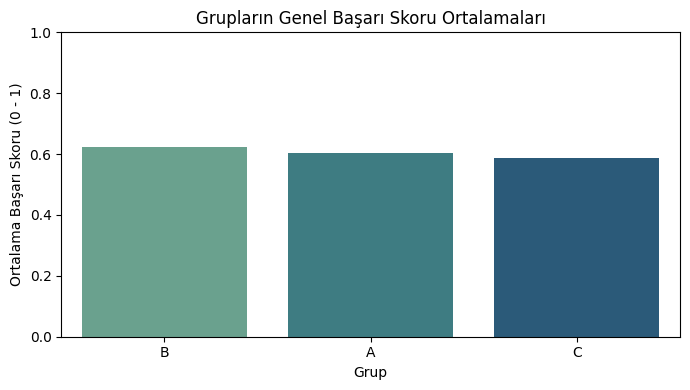

In [ ]:
ogrenci_basari_siralamasi = (
    df_ana_tablo.groupby(['No', 'Ad Soyad', 'Grup'])['Basari_Olcusu']
    .mean()
    .reset_index()
    .sort_values(by='Basari_Olcusu', ascending=False)
)

ogrenci_basari_siralamasi.index = range(1, len(ogrenci_basari_siralamasi) + 1)

print(f"--- Tüm Tarihler Üzerinden En Başarılı İlk {N} Öğrenci ---")
display(ogrenci_basari_siralamasi.head(N))


grup_basari_siralamasi = (
    df_ana_tablo.groupby('Grup')['Basari_Olcusu']
    .mean()
    .reset_index()
    .sort_values(by='Basari_Olcusu', ascending=False)
)

print("\n--- Grup Başarı Ortalamaları ---")
display(grup_basari_siralamasi)

en_iyi_grup = grup_basari_siralamasi.iloc[0]['Grup']
en_iyi_skor = grup_basari_siralamasi.iloc[0]['Basari_Olcusu']
print(f"\nEn Başarılı Grup: {en_iyi_grup} Grubu (Ortalama Başarı Skoru: {en_iyi_skor:.4f})")

plt.figure(figsize=(7, 4))
sns.barplot(
    data=grup_basari_siralamasi,
    x='Grup',
    y='Basari_Olcusu',
    hue='Grup',
    palette='crest',
    legend=False
)
plt.title("Grupların Genel Başarı Skoru Ortalamaları")
plt.xlabel("Grup")
plt.ylabel("Ortalama Başarı Skoru (0 - 1)")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### 6. Zaman İçindeki Değişim ve Eğilim Grafikleri (Madde 6 & 7)
Tarihsel eğilimleri kronolojik olarak izlemek için `Tarih` kolonu `datetime` formatına dönüştürülmüş ve iki ayrı zaman serisi çizgi grafiği üretilmiştir:
* **Madde 6 (Grupların Başarı Seyri):** Tarih ve grup bazında ortalama başarı skorları matris formatına getirilerek (`unstack`), A, B ve C gruplarının 13 gün boyunca sergilediği performans dalgalanmaları aynı eksen üzerinde çoklu çizgi grafiği olarak modellenmiştir.
* **Madde 7 (Günlük Sınav Ortalamasının Değişimi):** Gruplardan bağımsız olarak tüm sınıfın girdiği günlük sınavların ham not ortalaması (0–100 ölçeğinde) hesaplanmış, sınav zorluk düzeyinin zamana göre trendi çizgi grafiği ile sunulmuştur.

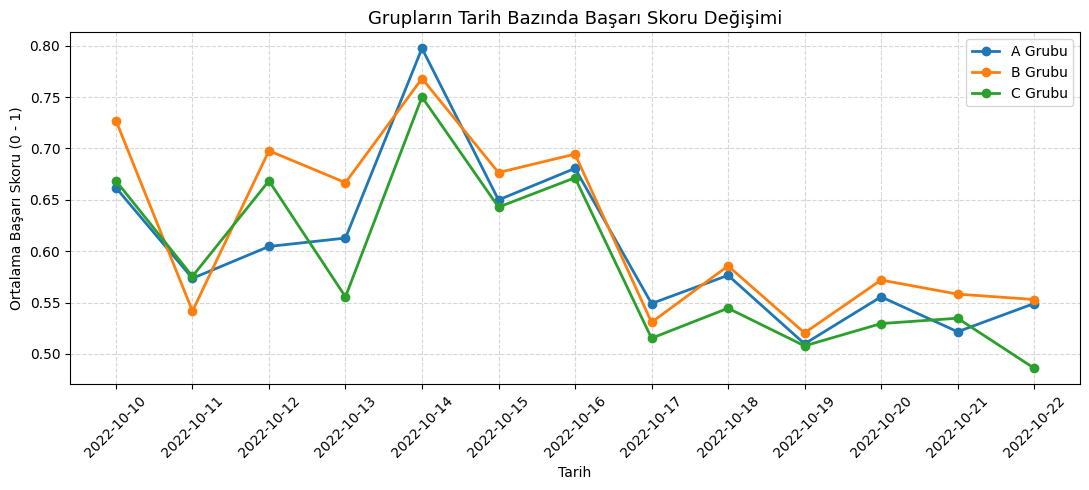

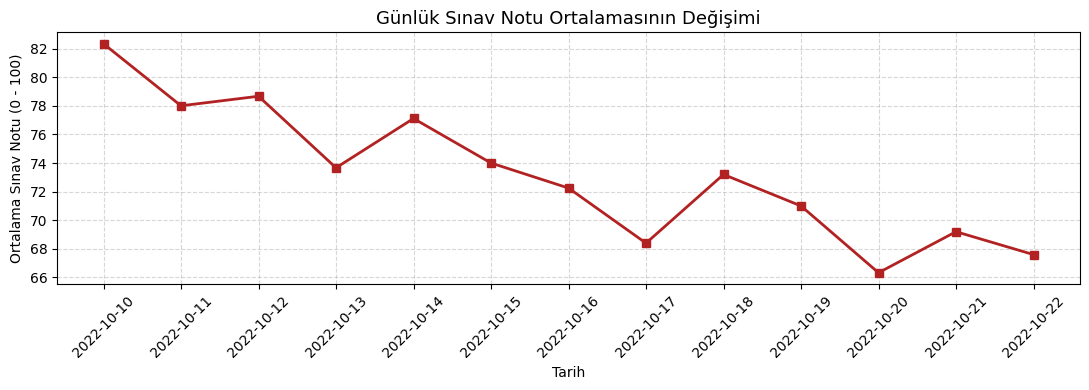

In [ ]:

df_ana_tablo['Tarih'] = pd.to_datetime(df_ana_tablo['Tarih'])


grup_zaman_serisi = df_ana_tablo.groupby(['Tarih', 'Grup'])['Basari_Olcusu'].mean().unstack()

plt.figure(figsize=(11, 5))
for grup in grup_zaman_serisi.columns:
    plt.plot(
        grup_zaman_serisi.index.strftime('%Y-%m-%d'),
        grup_zaman_serisi[grup],
        marker='o',
        linewidth=2,
        label=f'{grup} Grubu'
    )

plt.title("Grupların Tarih Bazında Başarı Skoru Değişimi", fontsize=13)
plt.xlabel("Tarih")
plt.ylabel("Ortalama Başarı Skoru (0 - 1)")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

gunluk_sinav_ort = df_ana_tablo.groupby('Tarih')['Not'].mean()

plt.figure(figsize=(11, 4))
plt.plot(
    gunluk_sinav_ort.index.strftime('%Y-%m-%d'),
    gunluk_sinav_ort.values,
    marker='s',
    color='firebrick',
    linewidth=2
)

plt.title("Günlük Sınav Notu Ortalamasının Değişimi", fontsize=13)
plt.xlabel("Tarih")
plt.ylabel("Ortalama Sınav Notu (0 - 100)")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 7. Tanımlayıcı İstatistikler ve Dağılım Analizi (Madde 8)
Veri setindeki üç temel sayısal değişken olan **Sınav Notu**, **Değerlendirme Puanı** ve hesaplanan **Başarı Skoru** için merkezi eğilim ve yayılım ölçüleri çıkarılmıştır:
* **Ortalama (Mean):** Değerlerin ağırlık merkezi.
* **Medyan (Median):** Sıralı verinin tam orta noktası.
* **Mod (Mode):** En sık tekrarlanan tepe değer.
* **Standart Sapma (Std):** Ortalamadan sapma ve varyasyon genişliği.

Hesaplanan değerler özet bir tablo halinde sunulmuş; ardından her üç değişkenin çeyreklik dilimleri ($Q1, Q3$), medyan çizgisi ve olası uç değerleri yan yana üç kutu grafiği (`boxplot`) ile görselleştirilmiştir.

--- Tanımlayıcı İstatistikler Tablosu ---


,Değişken,Ortalama,Medyan,Mod,Standart Sapma
0,Sınav Notu (0-100),73.21,100.00,100.0,39.87
1,Değerlendirme Puanı (0-10),4.30,5.00,5.0,2.63
2,Başarı Skoru (0-1),0.61,0.78,0.0,0.34


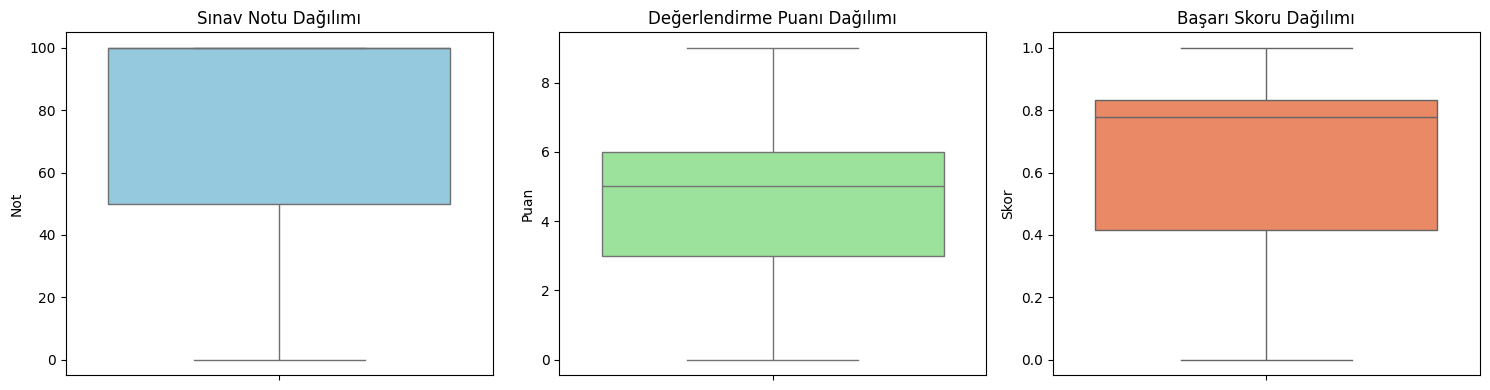

In [ ]:
def tanimlayici_istatistik_uret(seri, degisken_adi):
    return {
        "Değişken": degisken_adi,
        "Ortalama": round(seri.mean(), 2),
        "Medyan": round(seri.median(), 2),
        "Mod": round(seri.mode().iloc[0], 2) if not seri.mode().empty else np.nan,
        "Standart Sapma": round(seri.std(), 2)
    }

ozet_veriler = [
    tanimlayici_istatistik_uret(df_ana_tablo['Not'], "Sınav Notu (0-100)"),
    tanimlayici_istatistik_uret(df_ana_tablo['Puan'], "Değerlendirme Puanı (0-10)"),
    tanimlayici_istatistik_uret(df_ana_tablo['Basari_Olcusu'], "Başarı Skoru (0-1)")
]

df_tanimlayici = pd.DataFrame(ozet_veriler)

print("--- Tanımlayıcı İstatistikler Tablosu ---")
display(df_tanimlayici)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(y=df_ana_tablo['Not'], ax=axes[0], color="skyblue")
axes[0].set_title("Sınav Notu Dağılımı")
axes[0].set_ylabel("Not")

sns.boxplot(y=df_ana_tablo['Puan'], ax=axes[1], color="lightgreen")
axes[1].set_title("Değerlendirme Puanı Dağılımı")
axes[1].set_ylabel("Puan")

sns.boxplot(y=df_ana_tablo['Basari_Olcusu'], ax=axes[2], color="coral")
axes[2].set_title("Başarı Skoru Dağılımı")
axes[2].set_ylabel("Skor")

plt.tight_layout()
plt.show()

### 9. Araştırma Alanı: Sınav Notu ile Değerlendirme Puanı Arasındaki İlişki (Korelasyon Analizi)
**Araştırma Sorusu:** Öğrencilerin sınav notları (0–100) ile ders içi günlük performans değerlendirmeleri (0–10) arasında doğrusal bir ilişki var mıdır?

**Yöntem ve Bulgular:**
* Pearson korelasyon katsayısı **$r = 0.8896$** olarak hesaplanmış ve `regplot` ile saçılım grafiği çizilmiştir.
* Sonuç, kanaat notu ile sınav başarısı arasında çok güçlü ve pozitif bir bağ olduğunu doğrulamaktadır.

--- Sınav Notu ve Değerlendirme Puanı İlişkisi ---
Pearson Korelasyon Katsayısı (r): 0.8896


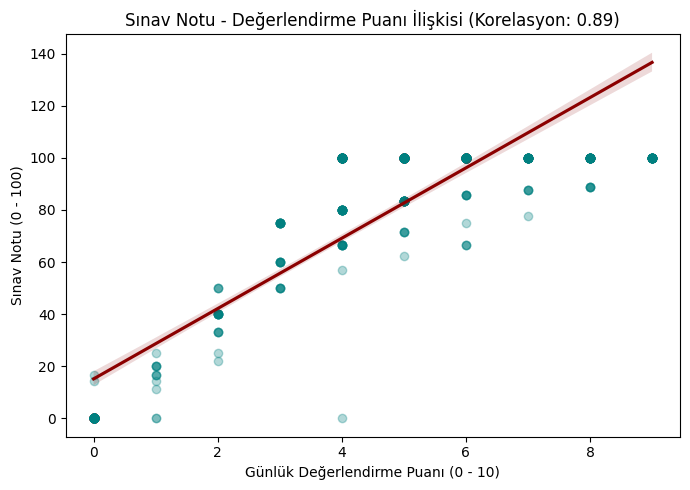

In [ ]:
korelasyon = df_ana_tablo['Not'].corr(df_ana_tablo['Puan'])

print("--- Sınav Notu ve Değerlendirme Puanı İlişkisi ---")
print(f"Pearson Korelasyon Katsayısı (r): {korelasyon:.4f}")

plt.figure(figsize=(7, 5))
sns.regplot(
    data=df_ana_tablo,
    x='Puan',
    y='Not',
    scatter_kws={'alpha': 0.3, 'color': 'teal'},
    line_kws={'color': 'darkred'}
)
plt.title(f"Sınav Notu - Değerlendirme Puanı İlişkisi (Korelasyon: {korelasyon:.2f})")
plt.xlabel("Günlük Değerlendirme Puanı (0 - 10)")
plt.ylabel("Sınav Notu (0 - 100)")
plt.tight_layout()
plt.show()

### 10. Araştırma Alanı: En Düşük Performans Gösterilen Günün Tespiti ve Şube Dayanıklılığı
**Araştırma Sorusu:** 13 günlük süreç boyunca sınıf genelinde başarının en dip noktaya gerilediği gün hangisidir ve bu günde şubelerin (A, B, C) başarı düzeyleri nasıl farklılaşmıştır?

**Yöntem ve Bulgular:**
* Sınıf genelinde en düşük başarı ortalamasının görüldüğü tarih **19 Ekim 2022** olarak saptanmıştır (Ortalama: **0.5128**).
* Bu zorlayıcı günde **B Grubu** (0.5204) diğer gruplara göre daha yüksek direnç sergilemiştir.

--- En Düşük Performans Gösterilen Günün Analizi ---
En Düşük Başarı Ortalamasına Sahip Gün: 2022-10-19
O Günün Genel Başarı Ortalaması: 0.5128

2022-10-19 Tarihindeki Grup Bazlı Dağılım:


,Grup,Not,Puan,Basari_Olcusu
0,A,70.588235,2.823529,0.509804
1,B,72.058824,2.882353,0.520425
2,C,70.312500,2.812500,0.507812


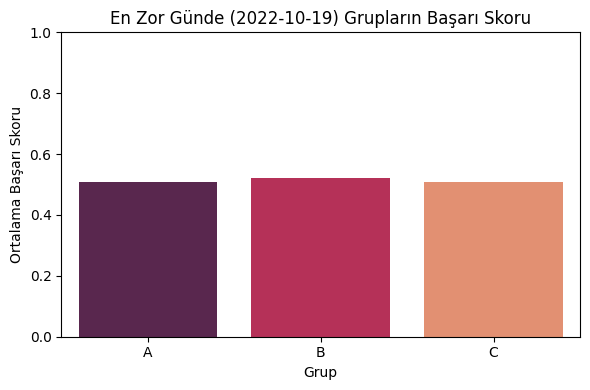

In [ ]:
gunluk_genel_basari = df_ana_tablo.groupby('Tarih')['Basari_Olcusu'].mean()
en_zor_tarih = gunluk_genel_basari.idxmin()
en_dusuk_skor = gunluk_genel_basari.min()

print("--- En Düşük Performans Gösterilen Günün Analizi ---")
print(f"En Düşük Başarı Ortalamasına Sahip Gün: {en_zor_tarih.strftime('%Y-%m-%d')}")
print(f"O Günün Genel Başarı Ortalaması: {en_dusuk_skor:.4f}")

en_zor_gun_grup_skorlari = (
    df_ana_tablo[df_ana_tablo['Tarih'] == en_zor_tarih]
    .groupby('Grup')[['Not', 'Puan', 'Basari_Olcusu']]
    .mean()
    .reset_index()
)
print(f"\n{en_zor_tarih.strftime('%Y-%m-%d')} Tarihindeki Grup Bazlı Dağılım:")
display(en_zor_gun_grup_skorlari)

plt.figure(figsize=(6, 4))
sns.barplot(
    data=en_zor_gun_grup_skorlari,
    x='Grup',
    y='Basari_Olcusu',
    hue='Grup',
    palette='rocket',
    legend=False
)
plt.title(f"En Zor Günde ({en_zor_tarih.strftime('%Y-%m-%d')}) Grupların Başarı Skoru")
plt.xlabel("Grup")
plt.ylabel("Ortalama Başarı Skoru")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()